## Segunda parte de la preparación: construcción y transformación de variables

En esta parte se realizan las tareas de construcción e integración de los datos de CRISP-DM. Como el
conjunto de datos no contiene variables numéricas directas, se construye una tabla resumen con una
fila por unidad organizacional y una serie de indicadores calculados a partir de sus jefaturas. Luego
se seleccionan las variables del modelo, se transforman y se estandarizan para que puedan utilizarse
con K-Means.

## 3.9 Carga de los datos limpios

Se parte del archivo generado al final de la limpieza. Las columnas de código se leen como texto,
igual que quedaron en la sección 3.3.

In [1]:
# Librerías utilizadas en esta parte
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import entropy
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

In [2]:
df_limpio = pd.read_csv(
    "../data/processed/jefaturas_limpio.csv",
    dtype={"cedula": str, "codigo_unidad": str}
)

print("Registros:", len(df_limpio))
print("Unidades:", df_limpio["codigo_unidad"].nunique())
df_limpio.head()

Registros: 1948
Unidades: 284


,cedula,codigo_unidad,unidad,puesto
0,107790683,1100,Gerencia General,Jefe Despacho Gerencia General
1,113570358,1101,Junta Directiva,Jefe Subárea de Sede
2,113750446,1101,Junta Directiva,Jefe Área de Sede
3,107960815,1102,Presidencia Ejecutiva,Asesor Coordinar Presidencia Ejecutiva
4,108340101,1103,Gerencia Financiera,Jefe Área de Sede


## 3.10 Construcción e integración de variables por unidad

Para cada unidad se calculan los siguientes indicadores:

| Variable | Cálculo | Qué representa |
|---|---|---|
| total_jefaturas | Cantidad de jefaturas de la unidad | Tamaño |
| puestos_distintos | Cantidad de puestos diferentes en la unidad | Diversidad |
| puesto_mas_frecuente | Puesto que más se repite en la unidad | Puesto predominante |
| frecuencia_puesto_principal | Cantidad de jefaturas del puesto que más se repite | Concentración (valor absoluto) |
| proporcion_puesto_principal | frecuencia_puesto_principal / total_jefaturas | Concentración (valor relativo) |
| proporcion_diversidad | puestos_distintos / total_jefaturas | Diversidad relativa |
| entropia_puestos | Entropía de Shannon de la distribución de puestos | Diversidad y equilibrio entre puestos |

Cada indicador se calcula por separado y luego se integran todos en una sola tabla, perfil_unidades,
con una fila por unidad.

In [3]:
perfil_unidades = (
    df_limpio.groupby(["codigo_unidad", "unidad"])
    .agg(
        total_jefaturas=("cedula", "count"),
        puestos_distintos=("puesto", "nunique")
    )
    .reset_index()
)

perfil_unidades.head(10)

,codigo_unidad,unidad,total_jefaturas,puestos_distintos
0,1100,Gerencia General,1,1
1,1101,Junta Directiva,2,2
2,1102,Presidencia Ejecutiva,1,1
3,1103,Gerencia Financiera,3,3
4,1104,Gerencia Administrativa,3,3
5,1105,Centro para la Instruccion de Procedimientos Administrativos,1,1
6,1106,Gerencia Logística,4,3
7,1107,Gerencia Infraestructura y Tecnologías,3,3
8,1111,Auditoria Interna,14,3
9,1112,Dirección Técnica Actuarial y Económica,6,3


In [4]:
puesto_principal = (
    df_limpio.groupby(["codigo_unidad", "unidad"])["puesto"]
    .agg(
        puesto_mas_frecuente=lambda serie: serie.value_counts().index[0],
        frecuencia_puesto_principal=lambda serie: serie.value_counts().iloc[0]
    )
    .reset_index()
)

perfil_unidades = perfil_unidades.merge(
    puesto_principal,
    on=["codigo_unidad", "unidad"],
    how="left"
)

perfil_unidades["proporcion_puesto_principal"] = (
    perfil_unidades["frecuencia_puesto_principal"]
    / perfil_unidades["total_jefaturas"]
)

perfil_unidades["proporcion_diversidad"] = (
    perfil_unidades["puestos_distintos"]
    / perfil_unidades["total_jefaturas"]
)

La entropía de Shannon mide qué tan repartidas están las jefaturas entre los distintos puestos. Vale 0
cuando todas las jefaturas de la unidad tienen el mismo puesto y aumenta cuanto más variados y
equilibrados son los puestos.

In [5]:
def calcular_entropia_puestos(serie):
    proporciones = serie.value_counts(normalize=True)
    return entropy(proporciones)

entropia_unidades = (
    df_limpio.groupby(["codigo_unidad", "unidad"])["puesto"]
    .apply(calcular_entropia_puestos)
    .reset_index(name="entropia_puestos")
)

perfil_unidades = perfil_unidades.merge(
    entropia_unidades,
    on=["codigo_unidad", "unidad"],
    how="left"
)

print("Unidades en la tabla resumen:", len(perfil_unidades))
print("Jefaturas sumadas:", perfil_unidades["total_jefaturas"].sum())
perfil_unidades.head(10)

Unidades en la tabla resumen: 284
Jefaturas sumadas: 1948


,codigo_unidad,unidad,total_jefaturas,puestos_distintos,puesto_mas_frecuente,frecuencia_puesto_principal,proporcion_puesto_principal,proporcion_diversidad,entropia_puestos
0,1100,Gerencia General,1,1,Jefe Despacho Gerencia General,1,1.000000,1.000000,0.000000
1,1101,Junta Directiva,2,2,Jefe Subárea de Sede,1,0.500000,1.000000,0.693147
2,1102,Presidencia Ejecutiva,1,1,Asesor Coordinar Presidencia Ejecutiva,1,1.000000,1.000000,0.000000
3,1103,Gerencia Financiera,3,3,Jefe Área de Sede,1,0.333333,1.000000,1.098612
4,1104,Gerencia Administrativa,3,3,Jefe Centro de Gestión Informatica Gerencial,1,0.333333,1.000000,1.098612
5,1105,Centro para la Instruccion de Procedimientos Administrativos,1,1,Director Institucional de Sede,1,1.000000,1.000000,0.000000
6,1106,Gerencia Logística,4,3,Jefe Área de Sede,2,0.500000,0.750000,1.039721
7,1107,Gerencia Infraestructura y Tecnologías,3,3,Jefe Área de Sede,1,0.333333,1.000000,1.098612
8,1111,Auditoria Interna,14,3,Jefe Subárea de Sede,8,0.571429,0.214286,0.876006
9,1112,Dirección Técnica Actuarial y Económica,6,3,Jefe Área de Sede,4,0.666667,0.500000,0.867563


In [6]:
variables_construidas = [
    "total_jefaturas",
    "puestos_distintos",
    "frecuencia_puesto_principal",
    "proporcion_puesto_principal",
    "proporcion_diversidad",
    "entropia_puestos"
]

perfil_unidades[variables_construidas].describe().round(3)

,total_jefaturas,puestos_distintos,frecuencia_puesto_principal,proporcion_puesto_principal,proporcion_diversidad,entropia_puestos
count,284.000,284.000,284.000,284.000,284.000,284.000
mean,6.859,5.398,2.099,0.502,0.909,1.186
std,8.740,5.261,3.565,0.368,0.189,0.951
min,1.000,1.000,1.000,0.067,0.200,0.000
25%,1.000,1.000,1.000,0.167,0.944,0.000
50%,6.000,4.000,1.000,0.414,1.000,1.271
75%,7.000,7.000,2.000,1.000,1.000,1.946
max,62.000,25.000,31.000,1.000,1.000,3.032


### Interpretación

La tabla resumen tiene 284 filas, una por unidad, y la suma de total_jefaturas es 1,948, igual a la
cantidad de registros limpios, lo que confirma que ninguna jefatura se perdió ni se contó dos veces
al agrupar.

Los valores son prácticamente iguales a los observados en la exploración (sección 2.3). La única
diferencia es el Hospital de Osa, que ahora tiene 13 jefaturas porque se eliminó el registro con
puesto #N/D.

## 3.11 Transformación de variables

En la exploración se observó que total_jefaturas tiene una asimetría positiva muy fuerte: la mayoría
de las unidades tiene pocas jefaturas y unas pocas tienen muchas. Para reducir el peso de esos valores
extremos se aplica la transformación logarítmica log1p.

In [7]:
perfil_unidades["log_total_jefaturas"] = np.log1p(
    perfil_unidades["total_jefaturas"]
)

perfil_unidades[
    ["total_jefaturas", "log_total_jefaturas"]
].describe().round(3)

,total_jefaturas,log_total_jefaturas
count,284.000,284.000
mean,6.859,1.684
std,8.740,0.835
min,1.000,0.693
25%,1.000,0.693
50%,6.000,1.946
75%,7.000,2.079
max,62.000,4.143


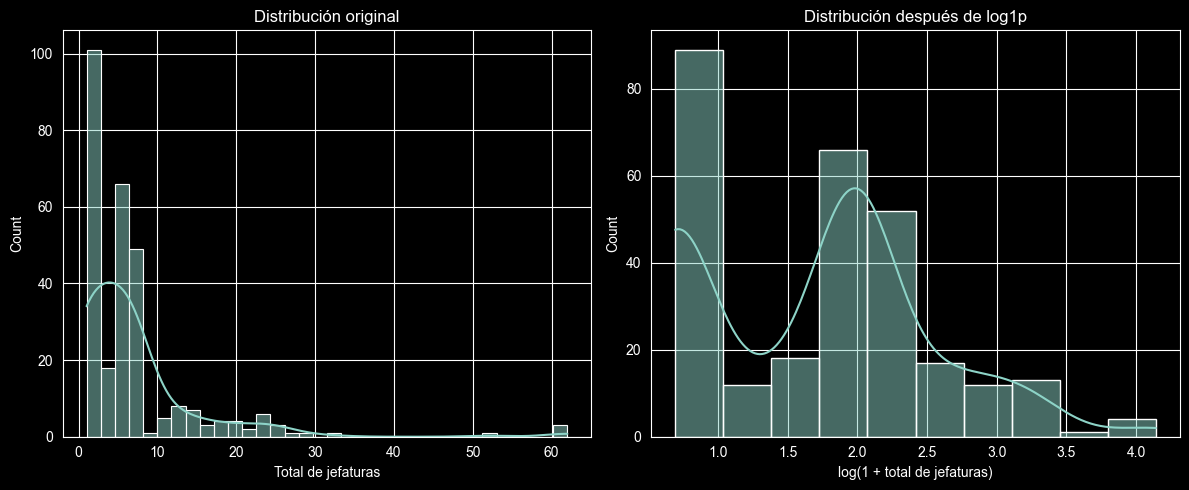

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    perfil_unidades["total_jefaturas"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribución original")
axes[0].set_xlabel("Total de jefaturas")

sns.histplot(
    perfil_unidades["log_total_jefaturas"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribución después de log1p")
axes[1].set_xlabel("log(1 + total de jefaturas)")

plt.tight_layout()
plt.show()

### Interpretación de la transformación

La variable total_jefaturas presentó una distribución marcadamente
asimétrica hacia la derecha, con valores entre 1 y 62. Para reducir la
influencia de las unidades de mayor tamaño se aplicó la transformación
logarítmica log1p, definida como el logaritmo natural de uno más el valor
original.

Después de la transformación, el rango de la variable se redujo de
1-62 a aproximadamente 0.693-4.143. El histograma muestra una disminución
considerable de la cola derecha y una distribución más equilibrada entre
las unidades pequeñas, medianas y grandes.

La transformación no busca hacer que los datos sean perfectamente
normales, ya que K-Means no exige normalidad. Su propósito es evitar que
las diferencias extremas en el tamaño de las unidades dominen el cálculo
de las distancias.

## 3.12 Selección de las variables del modelo

Para el modelado se busca representar tres dimensiones de cada unidad: tamaño, diversidad y
concentración, evitando incluir variables que repitan la misma información. Se seleccionaron:

log_total_jefaturas, como indicador del tamaño de la unidad.

entropia_puestos, como medida de diversidad estructural.

proporcion_puesto_principal, como medida de concentración.

Las demás variables se excluyen por las siguientes razones, observadas en la exploración:

| Variable excluida | Razón |
|---|---|
| total_jefaturas | Se reemplaza por su versión transformada, log_total_jefaturas |
| puestos_distintos | Tiene una correlación de 0.88 con el total de jefaturas, por lo que repite la información de tamaño; la entropía representa mejor la diversidad |
| frecuencia_puesto_principal | Tiene una correlación de 0.84 con el total de jefaturas; se usa su versión relativa, proporcion_puesto_principal |
| proporcion_diversidad | Vale 1 en el 74.65 % de las unidades, por lo que casi no permite diferenciarlas |

In [9]:
variables_modelo = [
    "log_total_jefaturas",
    "entropia_puestos",
    "proporcion_puesto_principal"
]

X = perfil_unidades[variables_modelo].copy()

X.describe().round(3)

,log_total_jefaturas,entropia_puestos,proporcion_puesto_principal
count,284.000,284.000,284.000
mean,1.684,1.186,0.502
std,0.835,0.951,0.368
min,0.693,0.000,0.067
25%,0.693,0.000,0.167
50%,1.946,1.271,0.414
75%,2.079,1.946,1.000
max,4.143,3.032,1.000


In [10]:
X.corr().round(3)

,log_total_jefaturas,entropia_puestos,proporcion_puesto_principal
log_total_jefaturas,1.000,0.910,-0.785
entropia_puestos,0.910,1.000,-0.942
proporcion_puesto_principal,-0.785,-0.942,1.000


Las correlaciones entre las tres variables son altas. Para entender por qué, se repite el cálculo sin
las 89 unidades que tienen una sola jefatura:

In [11]:
unidades_con_varias_jefaturas = perfil_unidades["total_jefaturas"] > 1

X[unidades_con_varias_jefaturas].corr().round(3)

,log_total_jefaturas,entropia_puestos,proporcion_puesto_principal
log_total_jefaturas,1.000,0.728,-0.209
entropia_puestos,0.728,1.000,-0.785
proporcion_puesto_principal,-0.209,-0.785,1.000


### Interpretación

Con todas las unidades, las tres variables están fuertemente correlacionadas: 0.91 entre el tamaño y
la entropía y -0.94 entre la entropía y la concentración. Gran parte de esa relación se debe a las 89
unidades con una sola jefatura, que tienen exactamente los mismos valores (el tamaño mínimo, entropía
0 y proporción 1) y forman un bloque en un extremo de las tres variables.

Al excluir esas unidades, las correlaciones bajan a 0.73 entre tamaño y entropía y a -0.21 entre
tamaño y concentración. Es decir, entre las unidades con más de una jefatura las variables sí aportan
información diferente: dos unidades del mismo tamaño pueden tener distinta diversidad y concentración,
como se observó en la exploración.

Se mantienen las tres variables porque representan dimensiones distintas del negocio, pero esta
relación se debe tener en cuenta al evaluar el modelo (sección 5.3).

## 3.13 Estandarización

K-Means calcula distancias entre las unidades. Como las variables tienen escalas distintas (la
proporción va de 0 a 1, mientras que la entropía llega a 3 y el logaritmo a más de 4), se estandarizan
con StandardScaler para que todas tengan media 0 y desviación estándar 1.

In [12]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_modelo,
    index=perfil_unidades.index
)

X_scaled.describe().round(3)

,log_total_jefaturas,entropia_puestos,proporcion_puesto_principal
count,284.000,284.000,284.000
mean,0.000,0.000,-0.000
std,1.002,1.002,1.002
min,-1.189,-1.249,-1.185
25%,-1.189,-1.249,-0.913
50%,0.314,0.089,-0.240
75%,0.474,0.801,1.353
max,2.950,1.944,1.353


### Interpretación de la estandarización

Las tres variables fueron estandarizadas mediante
StandardScaler. Los resultados presentan medias cercanas a cero y
desviaciones estándar cercanas a uno, lo que confirma que las variables
quedaron expresadas en una escala comparable.

Este procedimiento es necesario porque K-Means utiliza distancia
euclidiana. Sin la estandarización, una variable con mayor escala o
dispersión podría influir desproporcionadamente en la formación de los
conglomerados.

## 3.14 Guardar los datos preparados

Se guardan dos archivos para el modelado:

perfil_unidades.csv, con la tabla resumen completa de las 284 unidades.

modelo_X_estandarizado.csv, con las tres variables del modelo ya estandarizadas, en el mismo orden
de filas que la tabla resumen.

In [13]:
perfil_unidades.to_csv("../data/processed/perfil_unidades.csv", index=False, encoding="utf-8")
X_scaled.to_csv("../data/processed/modelo_X_estandarizado.csv", index=False, encoding="utf-8")

print("Archivos guardados en data/processed/")
print("perfil_unidades:", perfil_unidades.shape)
print("modelo_X_estandarizado:", X_scaled.shape)

Archivos guardados en data/processed/
perfil_unidades: (284, 10)
modelo_X_estandarizado: (284, 3)


### Conclusión de la preparación de los datos

A partir de 1,948 jefaturas limpias se construyó una tabla de 284 unidades con siete indicadores de
tamaño, diversidad y concentración. Se seleccionaron tres variables no redundantes, se transformó la
variable de tamaño con log1p para reducir su asimetría y se estandarizaron las tres para que tengan el
mismo peso en el cálculo de distancias. Los datos quedan listos para la fase de modelado.